#  Diabetes Prediction using Logistic Regression

---

### 📌 Project Overview

In this project, we will **predict whether a person has diabetes** based on health data like age, BMI, blood glucose level, and more.

| Step | What We Do |
|------|------------|
| 1️⃣ | Import Libraries |
| 2️⃣ | Load & Understand the Data |
| 3️⃣ | Exploratory Data Analysis (EDA) |
| 4️⃣ | Prepare Data for ML |
| 5️⃣ | Train Logistic Regression Model |
| 6️⃣ | Evaluate the Model |
| 7️⃣ | Predict on New Data |



---
##  Step 1 — Import Libraries

| Library | Purpose |
|---|---|
| `pandas` | Load and work with data (like Excel in Python) |
| `matplotlib` & `seaborn` | Create charts |
| `sklearn` | Machine Learning algorithms and tools |

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

---
##  Step 2 — Load the Dataset

In [ ]:
# import kagglehub
# from kagglehub import KaggleDatasetAdapter

# file_path = "diabetes_prediction_dataset.csv"

# df = kagglehub.load_dataset(
#   KaggleDatasetAdapter.PANDAS,
#   "iammustafatz/diabetes-prediction-dataset",
#   file_path,
# )
# df.head(5)

import pandas as pd
df = pd.read_csv("diabetes_prediction_dataset.csv")
df.head(5)

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


---
##  Step 3 — Exploratory Data Analysis (EDA)

EDA means **getting to know our data** before training a model.
We check for missing values, understand distributions, and spot patterns.

> 💡 Bad data → Bad model. EDA helps us catch issues early.
- ##### Check for Missing Values
- ##### Summary Statistics Shows count, mean, min, max for all numeric columns
- ##### Target Variable Distribution How many patients have diabetes vs do not?
- ##### Correlation Heatmap -   We want to see which features are most related to 'diabetes'

<Axes: >

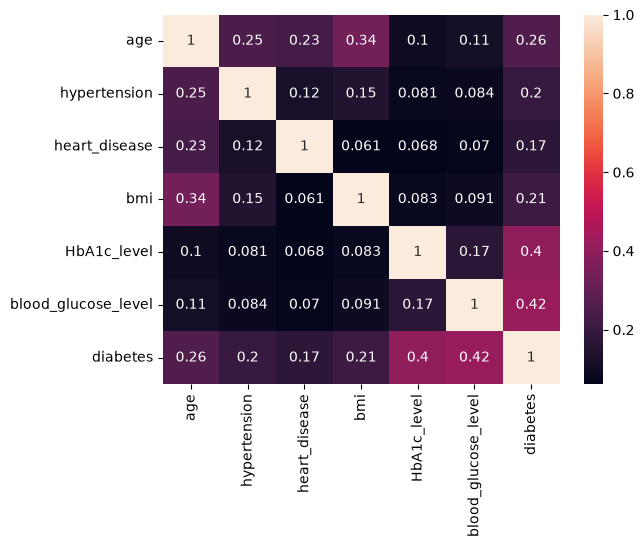

In [13]:
# null values
df.isnull().sum()

# summary stats
df.describe()

# Target Variable Distribution
df['diabetes'].value_counts()
sns.countplot(x='diabetes', data=df)

# # Correlation Heatmap
sns.heatmap(df.corr(numeric_only= True), annot = True)

---
## 🛠️ Step 4 — Data Preprocessing

ML models need **numbers**, not text. We also split data and scale it.

1. **Encode** text columns → numbers  
2. **Split** into Features `X` and Target `y`  
3. **Train-Test Split** — 80% train, 20% test  
4. **Scale** features so all values are on a similar range

In [14]:
cat_col = df.select_dtypes(include = 'object').columns
cat_col

for col in cat_col:
  print(f'{col} : {df[col].unique()}')

gender : <ArrowStringArray>
['Female', 'Male', 'Other']
Length: 3, dtype: str
smoking_history : <ArrowStringArray>
['never', 'No Info', 'current', 'former', 'ever', 'not current']
Length: 6, dtype: str


C:\Users\shrut\AppData\Local\Temp\ipykernel_13740\1593815854.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_col = df.select_dtypes(include = 'object').columns


In [15]:
#pd.dummies
df_copy=df.copy()

df_copy=pd.get_dummies(
    df_copy,
     cat_col,
     drop_first=True,
     dtype=int
)
df_copy.head()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,80.0,0,1,25.19,6.6,140,0,0,0,0,0,0,1,0
1,54.0,0,0,27.32,6.6,80,0,0,0,0,0,0,0,0
2,28.0,0,0,27.32,5.7,158,0,1,0,0,0,0,1,0
3,36.0,0,0,23.45,5.0,155,0,0,0,1,0,0,0,0
4,76.0,1,1,20.14,4.8,155,0,1,0,1,0,0,0,0


In [16]:
# Split X And y
X=df_copy.drop('diabetes',axis=1)
Y=df_copy['diabetes']  #input  (X) me se target col ko drop krke Y me daal diya

In [17]:
# Train test split
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.2,random_state=42)


---
## 🤖 Step 5 — Train Logistic Regression

**Logistic Regression** is the simplest and most interpretable classification model.

- Despite its name, it is used for **classification** (not regression)
- It predicts the **probability** of a patient having diabetes (0 or 1)
- Always a great starting point for any binary classification problem

In [18]:
from sklearn.linear_model import LogisticRegression
clf=LogisticRegression(random_state=0).fit(X,Y)
clf.fit(x_train,y_train)

C:\Users\shrut\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\shrut\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/mod

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",0
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following as

In [19]:
y_predict=clf.predict(x_test)
y_predict[:10]  #slicing

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [20]:
compare=pd.DataFrame({
    'Actual':y_test,
    "Predicted":y_predict
})
compare.head(10)

,Actual,Predicted
75721,0,0
80184,0,0
19864,0,0
76699,0,0
92991,1,0
76434,0,0
84004,0,0
80917,0,0
60767,0,0
50074,0,0


---
## 📊 Step 6 — Evaluate the Model

We measure performance using:

| Metric | Meaning |
|--------|----------|
| **Accuracy** | % of correct predictions overall |
| **Precision** | Of all predicted diabetic, how many truly are? |
| **Recall** | Of all actual diabetic patients, how many did we catch? |
| **F1-Score** | Balance between Precision and Recall |

> 🏥 In medical problems, **Recall** matters most — missing a diabetic patient is dangerous!

In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Actual values
y_actual = [0, 0, 0, 0, 1, 0, 0, 0, 0, 0]

# Model predictions
y_pred = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

accuracy = accuracy_score(y_actual, y_pred)
precision = precision_score(y_actual, y_pred)
recall = recall_score(y_actual, y_pred)
f1 = f1_score(y_actual, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)



Accuracy: 0.9
Precision: 0.0
Recall: 0.0
F1-Score: 0.0


C:\Users\shrut\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


---
## 🔮 Step 7 — Predict on New Patient Data

Let's test our model on a **manually entered patient** to see it in action.

> ✏️ Try changing the values below and re-run the cell to see different predictions!

In [22]:
new_patient = pd.DataFrame([{
    'gender' : 1,
    'age' : 50,
    'hypertension' : 1,
    'heart_disease' : 0,
    'smoking_history' : 0,
    'bmi' : 30,
    'HbA1c_level' : 7,
    'blood_glucose_level' : 180
}])

In [23]:
new_patient




,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level
0,1,50,1,0,0,30,7,180


In [24]:
new_patient = pd.get_dummies(
    new_patient,
    columns=cat_col,
    drop_first=True,
    dtype=int
)

In [25]:
new_patient = new_patient.reindex(columns=X.columns, fill_value=0)

In [26]:
print(new_patient.columns)

Index(['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level',
       'blood_glucose_level', 'gender_Male', 'gender_Other',
       'smoking_history_current', 'smoking_history_ever',
       'smoking_history_former', 'smoking_history_never',
       'smoking_history_not current'],
      dtype='str')


In [27]:
prediction = clf.predict(new_patient)

print(prediction)

[1]



## Step 8 — Save your model

In [28]:
import joblib
joblib.dump(clf,'finalModel.pkl')

['finalModel.pkl']

---
## ✅ Summary

| Step | What We Did |
|------|-------------|
| Load Data | 100,000 rows, 9 columns |
| EDA | Checked nulls, stats, class balance, correlations |
| Preprocessing | Label encoding, 80/20 split, StandardScaler |
| Model | Logistic Regression |
| Evaluation | Accuracy, Classification Report, Confusion Matrix |
| Prediction | Predicted diabetes for a new patient |

### 🚀 Next Steps
- Try **Random Forest** or **XGBoost** for potentially higher accuracy  
- Handle class imbalance using **SMOTE**  
- Tune the model with **GridSearchCV**  
- Build a simple web app using **Streamlit**

> 🎉 You completed a full ML project — this is the same workflow used in the real world!